# Reporting delay and calendar clustering in NUFORC public sighting reports

CSE558 Data Science, Monsoon 2026. Midterm project.

The raw file must be at `data/nuforc_reports.json` (see README).

## 0. Setup

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)

DATA_PATH = Path("data/nuforc_reports.json")
FIG_DIR = Path("figures")
OUT_DIR = Path("outputs")
FIG_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

assert DATA_PATH.exists(), f"Download the dataset to {DATA_PATH} (see README)"

print("python", sys.version.split()[0])
for m in (pd, np, scipy, matplotlib):
    print(m.__name__, m.__version__)

python 3.12.10
pandas 3.0.6
numpy 2.5.3
scipy 1.18.1
matplotlib 3.11.2


## 1. Raw inventory

Everything is read as text, so nothing changes before we count it. Blank strings count as missing.

In [2]:
raw = pd.read_json(DATA_PATH, lines=True, dtype=False)

n_rows, n_cols = raw.shape
print(f"rows: {n_rows:,}")
print(f"columns: {n_cols}")
print(f"cells (rows x columns): {n_rows:,} x {n_cols} = {n_rows * n_cols:,}")
print(f"meets 3,000,000 before encoding: {n_rows * n_cols >= 3_000_000}")
raw.head(3)

rows: 141,261
columns: 11
cells (rows x columns): 141,261 x 11 = 1,553,871
meets 3,000,000 before encoding: False


,text,stats,date_time,report_link,city,state,country,shape,duration,summary,posted
0,MADAR Node 100,Occurred : 6/23/2019 18:53 (Entered as : 06/2...,6/23/19 18:53,http://www.nuforc.org/webreports/reports/147/S...,Mountlake Terrace,WA,USA,NaN,NaN,MADAR Node 100,6/27/19
1,Steady flashing object with three lights hover...,Occurred : 6/23/2019 20:00 (Entered as : 6/23...,6/23/19 20:00,http://www.nuforc.org/webreports/reports/147/S...,Hamden,CT,USA,Light,5 hours,Steady flashing object with three lights hover...,6/27/19
2,"Group of several orange lights, seemingly circ...",Occurred : 6/20/2019 23:28 (Entered as : 06/2...,6/20/19 23:28,http://www.nuforc.org/webreports/reports/146/S...,Charlottesville,VA,USA,Circle,15 seconds,"Group of several orange lights, seemingly circ...",6/27/19


### Missing values

In [3]:
null = raw.isna().sum()
blank = raw.apply(lambda s: s.str.strip().eq("").sum())

before_fields = pd.DataFrame({
    "null": null,
    "blank": blank,
    "missing": null + blank,
    "missing_pct": ((null + blank) / n_rows * 100).round(2),
    "distinct": raw.nunique(dropna=True),
})
before_fields.index.name = "field"
before_fields

,null,blank,missing,missing_pct,distinct
field,,,,,
text,0,34,34,0.02,139329
stats,0,0,0,0.00,141247
date_time,101,0,101,0.07,120710
report_link,0,0,0,0.00,141261
city,459,0,459,0.32,28836
state,9551,0,9551,6.76,298
country,315,0,315,0.22,440
shape,6299,0,6299,4.46,39
duration,7596,0,7596,5.38,14011


### Duplicates

In [4]:
dup_full = raw.duplicated().sum()
dup_link = raw["report_link"].duplicated().sum()
dup_except_link = raw.drop(columns="report_link").duplicated().sum()

print(f"fully identical rows:              {dup_full:,}")
print(f"repeated report_link:              {dup_link:,}")
print(f"identical in every field but link: {dup_except_link:,}")

fully identical rows:              0
repeated report_link:              0
identical in every field but link: 0


In [5]:
before_summary = pd.Series({
    "rows": n_rows,
    "columns": n_cols,
    "cells": n_rows * n_cols,
    "rows_with_any_missing": int((raw.isna() | raw.apply(lambda s: s.str.strip().eq(""))).any(axis=1).sum()),
    "duplicate_full_rows": int(dup_full),
    "duplicate_report_link": int(dup_link),
    "duplicate_except_link": int(dup_except_link),
}, name="before")

before_summary.to_csv(OUT_DIR / "before_summary.csv", header=True)
before_fields.to_csv(OUT_DIR / "before_fields.csv")
before_summary

rows                      141261
columns                       11
cells                    1553871
rows_with_any_missing      19565
duplicate_full_rows            0
duplicate_report_link          0
duplicate_except_link          0
Name: before, dtype: int64

## 2. Cleaning

### Null-like strings

Some fields contain the word `null` instead of being empty, so we treat it as missing.

In [6]:
clean = raw.copy()

NULL_LIKE = {"null", "none", "nan", "n/a"}
null_like = clean.apply(lambda s: s.str.strip().str.lower().isin(NULL_LIKE))
blank_str = clean.apply(lambda s: s.str.strip().eq(""))
print("null-like strings set to missing:")
print(null_like.sum()[null_like.sum() > 0].to_string())
print("blank strings set to missing:")
print(blank_str.sum()[blank_str.sum() > 0].to_string())
clean = clean.mask(null_like | blank_str)

null-like strings set to missing:
city        13
state       29
country      1
duration    26
summary      1
blank strings set to missing:
text    34


### Re-posted reports

A few reports were posted twice with the exact same `stats` header, down to the second they were submitted. We keep the first copy.

In [7]:
repost = clean["stats"].duplicated(keep="first")
print(f"re-posted submissions dropped: {repost.sum()}")
clean = clean[~repost].reset_index(drop=True)
print(f"rows now: {len(clean):,}")

re-posted submissions dropped: 14
rows now: 141,247


### Dates

The `Occurred` date in `stats` has a four-digit year, so we use it and only fall back to `date_time` when it's missing.

If a witness only typed a year or a month, NUFORC fills in the 1st, so those dates are flagged as not precise.

A delay of exactly -1 day is most likely a time-zone mismatch, so only delays below -1 are flagged as errors.

In [8]:
st = clean["stats"]

occ_date = pd.to_datetime(st.str.extract(r"Occurred\s*:\s*(\d{1,2}/\d{1,2}/\d{4})")[0], format="%m/%d/%Y", errors="coerce")
occ_time = st.str.extract(r"Occurred\s*:\s*\d{1,2}/\d{1,2}/\d{4}\s+(\d{1,2}:\d{2})")[0]

dt_parts = clean["date_time"].str.extract(r"^(\d{1,2}/\d{1,2}/\d{2})(?:\s+(\d{1,2}:\d{2}))?$")
fb_date = pd.to_datetime(dt_parts[0], format="%m/%d/%y", errors="coerce")
fb_date = fb_date.mask(fb_date.dt.year > 2022, fb_date - pd.DateOffset(years=100))
use_fb = occ_date.isna() & fb_date.notna()

occ_date = occ_date.where(~use_fb, fb_date)
occ_time = occ_time.where(~use_fb, dt_parts[1])

hh = pd.to_numeric(occ_time.str.split(":").str[0], errors="coerce")
mm = pd.to_numeric(occ_time.str.split(":").str[1], errors="coerce")
rollover = hh.eq(24)
print(f"24:xx clock times rolled to next day: {rollover.sum()}")
occ_date = occ_date + pd.to_timedelta(rollover.astype(int), unit="D")
hh = hh.mask(rollover, 0)
hh = hh.where(hh.between(0, 23) & mm.between(0, 59))

entered = st.str.extract(r"Entered as\s*:\s*([^)]*)\)")[0].str.strip()
precise_entry = entered.str.match(r"^(\d{1,2}[/-]\d{1,2}[/-]\d{2,4}|\d{6}(\d{2})?)(\s|$)", na=False)

rep_dt = pd.to_datetime(st.str.extract(r"Reported\s*:\s*(\d{1,2}/\d{1,2}/\d{4})")[0], format="%m/%d/%Y", errors="coerce")
posted_dt = pd.to_datetime(st.str.extract(r"Posted\s*:\s*(\d{1,2}/\d{1,2}/\d{4})")[0], format="%m/%d/%Y", errors="coerce")

clean["date_source"] = np.select([occ_date.notna() & ~use_fb, use_fb], ["stats", "date_time"], "none")
clean["occurred_date"] = occ_date
clean["year_implausible"] = occ_date.dt.year < 1900
clean["date_ok"] = occ_date.notna() & ~clean["year_implausible"]
clean["date_precise"] = clean["date_ok"] & (precise_entry | use_fb)
clean["year"] = occ_date.dt.year.astype("Int64")
clean["month"] = occ_date.dt.month.astype("Int64")
clean["day"] = occ_date.dt.day.astype("Int64")
clean["weekday"] = occ_date.dt.dayofweek.astype("Int64")
clean["is_weekend"] = clean["weekday"].isin([5, 6]).where(occ_date.notna())
clean["hour"] = hh.astype("Int64")
clean["time_ok"] = clean["date_ok"] & clean["hour"].notna()

clean["reported_date"] = rep_dt
clean["posted_date"] = posted_dt
clean["lag_reported_days"] = (clean["reported_date"] - occ_date).dt.days.astype("Int64")
clean["lag_posted_days"] = (clean["posted_date"] - occ_date).dt.days.astype("Int64")
clean["lag_error"] = clean["lag_reported_days"] < -1

print(clean["date_source"].value_counts().to_string())
print(f"reported parsed: {rep_dt.notna().sum():,}   posted parsed: {posted_dt.notna().sum():,}")
print(f"years before 1900 flagged: {clean['year_implausible'].sum()}")
print(f"date_ok: {clean['date_ok'].sum():,}   date_precise: {clean['date_precise'].sum():,}   time_ok: {clean['time_ok'].sum():,}")
print(f"reporting delay of exactly -1 day: {(clean['lag_reported_days'] == -1).sum():,}")
print(f"reporting delay below -1 day, flagged lag_error: {clean['lag_error'].sum():,}")
print(f"posted before reported: {(clean['posted_date'] < clean['reported_date']).sum()}")

24:xx clock times rolled to next day: 0


date_source
stats        140872
none            366
date_time         9
reported parsed: 141,247   posted parsed: 141,247
years before 1900 flagged: 20
date_ok: 140,861   date_precise: 129,836   time_ok: 139,134
reporting delay of exactly -1 day: 2,759
reporting delay below -1 day, flagged lag_error: 182
posted before reported: 0


Imprecise dates should land on the 1st far more often than precise ones:

In [9]:
ok = clean[clean["date_ok"]]
print(ok.groupby("date_precise")["day"].apply(lambda d: f"{(d == 1).mean():.1%} on day 1  (n = {len(d):,})").to_string())

date_precise
False    20.0% on day 1  (n = 11,025)
True     5.0% on day 1  (n = 129,836)


### Duration

Ranges take the midpoint and things like `1 hr 30 min` are added up. Text with no number (`few minutes`, `ongoing`) stays missing rather than being filled in.

In [10]:
import re

UNIT_SECONDS = {
    "s": 1, "sec": 1, "secs": 1, "second": 1, "seconds": 1, "seg": 1, "segundos": 1,
    "m": 60, "min": 60, "mins": 60, "minute": 60, "minutes": 60, "minuets": 60, "minuts": 60, "minits": 60, "mns": 60,
    "h": 3600, "hr": 3600, "hrs": 3600, "hour": 3600, "hours": 3600, "hora": 3600, "horas": 3600,
    "day": 86400, "days": 86400,
}
WORD_NUMBERS = {
    "a": 1, "an": 1, "one": 1, "two": 2, "three": 3, "four": 4, "five": 5, "six": 6, "seven": 7,
    "eight": 8, "nine": 9, "ten": 10, "eleven": 11, "twelve": 12, "fifteen": 15, "twenty": 20,
    "thirty": 30, "forty": 40, "fourty": 40, "forty-five": 45, "fifty": 50, "sixty": 60, "ninety": 90,
    "couple": 2, "a couple": 2,
}
_NUM = r"\d+(?:\.\d+)?(?:\s*1/2)?|\d+/\d+|" + "|".join(sorted(map(re.escape, WORD_NUMBERS), key=len, reverse=True))
_UNIT = "|".join(sorted(map(re.escape, UNIT_SECONDS), key=len, reverse=True))
_PAIR = re.compile(rf"(?<![a-z])(?P<a>{_NUM})(?:\s*(?:-|to|or)\s*(?P<b>{_NUM}))?\s*(?:\+\s*)?(?P<u>{_UNIT})\.?(?![a-z])")


def _to_number(tok):
    tok = tok.strip()
    if tok in WORD_NUMBERS:
        return WORD_NUMBERS[tok]
    if m := re.fullmatch(r"(\d+)\s*1/2", tok):
        return int(m.group(1)) + 0.5
    if re.fullmatch(r"\d+/\d+", tok):
        n, d = map(int, tok.split("/"))
        return n / d if d else np.nan
    return float(tok)


def parse_duration(text):
    if not isinstance(text, str):
        return np.nan
    t = text.lower().replace("½", " 1/2")
    t = re.sub(r"(\d+):(\d{2})\s*(?=[a-z])", lambda m: f"{int(m.group(1)) + int(m.group(2)) / 60:g} ", t)
    t = re.sub(r"(\d)\s*(?=[a-z])", r"\1 ", t)
    t = re.sub(r"(?<=[a-z])(?=\d)", " ", t)
    t = re.sub(r"\b(one|two|three|four|five|ten|twenty|thirty)(?=(sec|min|hour|hr))", r"\1 ", t)
    t = re.sub(r"\bhalf\s+(?:an|a)\s+hour\b|\bhalf\s*hour\b", "0.5 hour", t)
    pairs = list(_PAIR.finditer(t))
    if not pairs:
        return np.nan
    values = []
    for m in pairs:
        a = _to_number(m.group("a"))
        b = _to_number(m.group("b")) if m.group("b") else a
        values.append((a + b) / 2 * UNIT_SECONDS[m.group("u")])
    if len(values) == 1:
        return values[0]
    if re.search(r"-|\bto\b|\bor\b", t[pairs[0].end():pairs[1].start()]):
        return (values[0] + values[1]) / 2
    return sum(values)


examples = ["5 minutes", "2-3 minutes", "~5 mins", "1 hr 30 min", "30 seconds - 1 minute", "15minutes",
            "half an hour", "1 1/2 hours", "1:30 min", "2 Hours +", "a few seconds", "ongoing", "10", "22:31"]
pd.DataFrame({"duration": examples, "seconds": [parse_duration(x) for x in examples]})

,duration,seconds
0,5 minutes,300.0
1,2-3 minutes,150.0
2,~5 mins,300.0
3,1 hr 30 min,5400.0
4,30 seconds - 1 minute,45.0
5,15minutes,900.0
6,half an hour,1800.0
7,1 1/2 hours,5400.0
8,1:30 min,90.0
9,2 Hours +,7200.0


In [11]:
clean["duration_seconds"] = clean["duration"].map(parse_duration)
clean["duration_seconds"] = clean["duration_seconds"].where(clean["duration_seconds"] > 0)
clean["duration_ok"] = clean["duration_seconds"].notna()

has_text = clean["duration"].notna()
print(f"duration text present: {has_text.sum():,}")
print(f"parsed to seconds:     {clean['duration_ok'].sum():,} ({clean['duration_ok'].sum() / has_text.sum():.1%} of present)")
print(f"left missing:          {(~clean['duration_ok']).sum():,} (no text: {(~has_text).sum():,}, text not parseable: {(has_text & ~clean['duration_ok']).sum():,})")
print("\nmost common unparsed strings:")
print(clean.loc[has_text & ~clean["duration_ok"], "duration"].str.strip().str.lower().value_counts().head(15).to_string())
print("\nduration_seconds quantiles:")
print(clean["duration_seconds"].quantile([0, 0.25, 0.5, 0.75, 0.99, 1]).to_string())

duration text present: 133,626
parsed to seconds:     120,402 (90.1% of present)
left missing:          20,845 (no text: 7,621, text not parseable: 13,224)

most common unparsed strings:
duration
seconds            811
unknown            807
ongoing            316
few seconds        279
?                  231
hours              224
a few seconds      220
10                 215
few minutes        202
several minutes    196
15                 184
minutes            178
30                 176
not sure           140
all night          138

duration_seconds quantiles:
0.00    1.000000e-03
0.25    3.000000e+01
0.50    1.800000e+02
0.75    6.000000e+02
0.99    1.080000e+04
1.00    8.280000e+07


### Shape

Labels are lower-cased, missing becomes `unknown`, and labels with under 1,000 reports go into `other`.

In [12]:
clean["shape_missing"] = clean["shape"].isna()
clean["shape_clean"] = clean["shape"].str.strip().str.lower().fillna("unknown")
shape_counts = clean["shape_clean"].value_counts()
rare_shapes = shape_counts[shape_counts < 1000].index.tolist()
clean["shape_group"] = clean["shape_clean"].mask(clean["shape_clean"].isin(rare_shapes), "other")

print(f"distinct raw labels: {clean['shape'].nunique()}  ->  after lower-case: {clean['shape_clean'].nunique()}  ->  grouped: {clean['shape_group'].nunique()}")
print(f"merged into 'other': {rare_shapes}")
print(f"missing shape mapped to 'unknown': {clean['shape_missing'].sum():,}")
clean["shape_group"].value_counts().to_frame("reports")

distinct raw labels: 39  ->  after lower-case: 23  ->  grouped: 19


merged into 'other': ['cone', 'cross', 'star', 'delta']
missing shape mapped to 'unknown': 6,298


,reports
shape_group,
light,28504
unknown,15861
circle,15080
triangle,12607
other,10849
fireball,9678
sphere,9174
disk,8338
oval,6115


### Country and state

The different spellings of each country are mapped to USA, Canada, United Kingdom, Australia, other or unknown.

In [13]:
COUNTRY_ALIASES = {
    "USA": {"usa", "us", "u.s.a", "u.s", "united states", "united states of america", "untied states of america",
            "usausa", "usav", "america"},
    "Canada": {"canada"},
    "United Kingdom": {"united kingdom", "uk", "u.k", "uk/england", "england", "scotland", "wales", "north wales",
                       "uk/wales", "great britain", "britain", "northern ireland"},
    "Australia": {"australia", "western australia"},
}
alias_to_group = {a: g for g, aliases in COUNTRY_ALIASES.items() for a in aliases}

country_key = clean["country"].str.strip().str.lower().str.replace(r"\s+", " ", regex=True).str.rstrip(".")
clean["country_group"] = country_key.map(alias_to_group).fillna("other").mask(clean["country"].isna(), "unknown")

US_STATES = set("AL AK AZ AR CA CO CT DE FL GA HI ID IL IN IA KS KY LA ME MD MA MI MN MS MO MT NE NV NH NJ NM NY "
                "NC ND OH OK OR PA RI SC SD TN TX UT VT VA WA WV WI WY DC".split())
state_code = clean["state"].str.strip().str.upper()
clean["us_state"] = state_code.where(state_code.isin(US_STATES) & clean["country_group"].eq("USA"))

print(f"distinct country spellings: {clean['country'].nunique()}  ->  groups: {clean['country_group'].nunique()}")
print(clean["country_group"].value_counts().to_string())
usa = clean["country_group"].eq("USA")
print(f"\nUSA rows with a valid state code: {clean.loc[usa, 'us_state'].notna().sum():,} of {usa.sum():,}")

distinct country spellings: 439  ->  groups: 6
country_group
USA               125863
Canada              5706
other               5292
United Kingdom      3183
Australia            887
unknown              316

USA rows with a valid state code: 125,436 of 125,863


### Junk and hoax flags

MADAR rows are automatic sensor alerts, not people. Hoax notes come from NUFORC, so we flag them instead of dropping them.

In [14]:
text = clean["text"].fillna("")
clean["is_madar"] = text.str.contains(r"MADAR\s+Node", case=False)
clean["text_empty"] = clean["text"].isna()
clean["nuforc_hoax"] = (clean["summary"].fillna("") + " " + text).str.contains(r"\(\(\s*HOAX", case=False)
clean["is_junk"] = clean["is_madar"] | clean["text_empty"]

for f in ["is_madar", "text_empty", "is_junk", "nuforc_hoax"]:
    print(f"{f:12s} {clean[f].sum():6,}")
print(f"MADAR rows with no shape: {clean.loc[clean['is_madar'], 'shape_missing'].mean():.1%}, "
      f"with no duration: {(~clean.loc[clean['is_madar'], 'duration_ok']).mean():.1%}")

is_madar      2,044
text_empty       34
is_junk       2,078
nuforc_hoax   1,288
MADAR rows with no shape: 99.6%, with no duration: 99.6%


### Cleaning log

In [15]:
cleaning_log = pd.DataFrame([
    ("re-posted submissions", "dropped", int(repost.sum())),
    ("null-like strings", "set to missing", int(null_like.values.sum())),
    ("occurred date from date_time fallback", "parsed", int((clean["date_source"] == "date_time").sum())),
    ("no occurred date", "flagged date_ok = False", int((clean["date_source"] == "none").sum())),
    ("year before 1900", "flagged year_implausible", int(clean["year_implausible"].sum())),
    ("imprecise date (year or month only)", "flagged date_precise = False", int((clean["date_ok"] & ~clean["date_precise"]).sum())),
    ("no clock time", "flagged time_ok = False", int((clean["date_ok"] & ~clean["time_ok"]).sum())),
    ("reported 1 day before occurred (time zone)", "kept as same-night report", int((clean["lag_reported_days"] == -1).sum())),
    ("reported 2+ days before occurred", "flagged lag_error", int(clean["lag_error"].sum())),
    ("duration parsed", "duration_seconds", int(clean["duration_ok"].sum())),
    ("duration missing or unparseable", "flagged duration_ok = False", int((~clean["duration_ok"]).sum())),
    ("shape missing", "mapped to 'unknown'", int(clean["shape_missing"].sum())),
    ("rare shape labels", "merged into 'other'", int(clean["shape_clean"].isin(rare_shapes).sum())),
    ("country missing", "mapped to 'unknown'", int((clean["country_group"] == "unknown").sum())),
    ("MADAR machine alerts", "flagged is_madar", int(clean["is_madar"].sum())),
    ("empty text", "flagged text_empty", int(clean["text_empty"].sum())),
    ("NUFORC hoax note", "flagged nuforc_hoax", int(clean["nuforc_hoax"].sum())),
], columns=["issue", "action", "rows"])

cleaning_log.to_csv(OUT_DIR / "cleaning_log.csv", index=False)
print(f"rows after cleaning: {len(clean):,}   columns: {clean.shape[1]}")
cleaning_log

rows after cleaning: 141,247   columns: 39


,issue,action,rows
0,re-posted submissions,dropped,14
1,null-like strings,set to missing,70
2,occurred date from date_time fallback,parsed,9
3,no occurred date,flagged date_ok = False,366
4,year before 1900,flagged year_implausible,20
5,imprecise date (year or month only),flagged date_precise = False,11025
6,no clock time,flagged time_ok = False,1727
7,reported 1 day before occurred (time zone),kept as same-night report,2759
8,reported 2+ days before occurred,flagged lag_error,182
9,duration parsed,duration_seconds,120402


## 3. Encoding and size check

Shape, country and month are one-hot encoded. City isn't, since its 28,000+ names would add a column per town for very little information.

In [16]:
numeric_cols = ["year", "day", "hour", "weekday", "duration_seconds", "lag_reported_days", "lag_posted_days"]
flag_cols = ["is_weekend", "date_ok", "date_precise", "time_ok", "year_implausible", "lag_error",
             "duration_ok", "shape_missing", "is_madar", "text_empty", "nuforc_hoax"]

numeric = clean[numeric_cols].astype("float64")
flags = clean[flag_cols].astype("boolean").fillna(False).astype("int8")
shape_oh = pd.get_dummies(clean["shape_group"], prefix="shape", dtype="int8")
country_oh = pd.get_dummies(clean["country_group"], prefix="country", dtype="int8")
month_oh = pd.get_dummies(clean["month"].astype(pd.CategoricalDtype(range(1, 13))), prefix="month", dtype="int8")

encoded = pd.concat([numeric, flags, shape_oh, country_oh, month_oh], axis=1)
encoded.index = clean["report_link"]

blocks = pd.DataFrame({
    "block": ["numeric", "flags", "shape one-hot", "country one-hot", "month one-hot"],
    "columns": [numeric.shape[1], flags.shape[1], shape_oh.shape[1], country_oh.shape[1], month_oh.shape[1]],
})
blocks

,block,columns
0,numeric,7
1,flags,11
2,shape one-hot,19
3,country one-hot,6
4,month one-hot,12


In [17]:
enc_rows, enc_cols = encoded.shape
size_check = pd.DataFrame({
    "rows": [n_rows, enc_rows],
    "columns": [n_cols, enc_cols],
    "cells": [n_rows * n_cols, enc_rows * enc_cols],
}, index=["raw file", "after encoding"])
size_check["meets_3M"] = size_check["cells"] >= 3_000_000
size_check.to_csv(OUT_DIR / "size_check.csv")

print(f"{enc_rows:,} x {enc_cols} = {enc_rows * enc_cols:,} cells")
print(f"meets 3,000,000: {enc_rows * enc_cols >= 3_000_000}")
size_check

141,247 x 55 = 7,768,585 cells
meets 3,000,000: True


,rows,columns,cells,meets_3M
raw file,141261,11,1553871,False
after encoding,141247,55,7768585,True


## 4. Exploration / confirmation split (seed 42)

Reports are split at random rather than by year, so both sets cover the same years. The ID lists are saved so the exact split can be rebuilt.

In [18]:
explore = clean.sample(frac=0.8, random_state=SEED)
confirm = clean.drop(explore.index)

assert not explore["report_link"].isin(confirm["report_link"]).any()
assert len(explore) + len(confirm) == len(clean)

explore["report_link"].to_csv(OUT_DIR / "explore_ids.csv", index=False)
confirm["report_link"].to_csv(OUT_DIR / "confirm_ids.csv", index=False)

print(f"exploration:  {len(explore):,} ({len(explore) / len(clean):.1%})")
print(f"confirmation: {len(confirm):,} ({len(confirm) / len(clean):.1%})")

exploration:  112,998 (80.0%)
confirmation: 28,249 (20.0%)


Both sets need enough July reports and enough early and late filers for the tests:

In [19]:
def split_counts(d):
    people = d[~d["is_junk"]]
    july = people[(people["date_precise"] & people["month"].eq(7)).fillna(False)]
    lag = people["lag_reported_days"]
    usable = people["duration_ok"] & ~people["lag_error"]
    return pd.Series({
        "reports": len(d),
        "precise July dates": len(july),
        "on July 4th": int(july["day"].eq(4).sum()),
        "July 4th share": round(july["day"].eq(4).mean(), 4),
        "duration, filed within 7 days": int((usable & lag.le(7)).fillna(False).sum()),
        "duration, filed after 30 days": int((usable & lag.gt(30)).fillna(False).sum()),
    }, dtype=object)


split_check = pd.DataFrame({"exploration": split_counts(explore), "confirmation": split_counts(confirm)})
split_check.to_csv(OUT_DIR / "split_check.csv")
split_check

,exploration,confirmation
reports,112998,28249
precise July dates,12209,3012
on July 4th,1613,436
July 4th share,0.1321,0.1448
"duration, filed within 7 days",67658,16826
"duration, filed after 30 days",21595,5470


## 5. EDA (exploration set only)

Everything in this section uses the exploration set only, without MADAR and empty-text rows.

In [20]:
people = explore[~explore["is_junk"]].copy()
dated = people[people["date_ok"]]
timed = people[people["time_ok"]]

plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
GREY, RED = "#9aa5b1", "#c0392b"


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight", metadata={"CreationDate": None})
    fig.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show()


print(f"reports used: {len(people):,}")

reports used: 111,371


### Obvious questions

In [21]:
top_states = people["us_state"].value_counts()
top_shapes = people["shape_clean"].value_counts()
night = (timed["hour"] >= 18) | (timed["hour"] < 6)
per_year = dated["year"].value_counts().sort_index()

print("Most reports by US state:")
print((top_states.head(5) / top_states.sum()).map("{:.1%}".format).to_string())
print("\nMost common shapes:")
print((top_shapes.head(5) / len(people)).map("{:.1%}".format).to_string())
print(f"\nreported between 18:00 and 05:59: {night.mean():.1%}  (12 of 24 hours = 50%)")
print(f"on a weekend: {dated['is_weekend'].astype(bool).mean():.1%}  (2 of 7 days = 28.6%)")
print(f"\nbusiest year: {per_year.idxmax()} ({per_year.max():,} reports)")
print(f"share from 1998 on: {per_year[per_year.index >= 1998].sum() / per_year.sum():.1%}")

Most reports by US state:
us_state
CA    12.4%
FL     6.2%
WA     5.5%
TX     4.7%
NY     4.5%

Most common shapes:
shape_clean
light       20.5%
circle      10.8%
unknown      9.9%
triangle     9.0%
other        7.0%

reported between 18:00 and 05:59: 79.4%  (12 of 24 hours = 50%)
on a weekend: 32.3%  (2 of 7 days = 28.6%)

busiest year: 2014 (7,030 reports)
share from 1998 on: 89.7%


### Reports per day of July

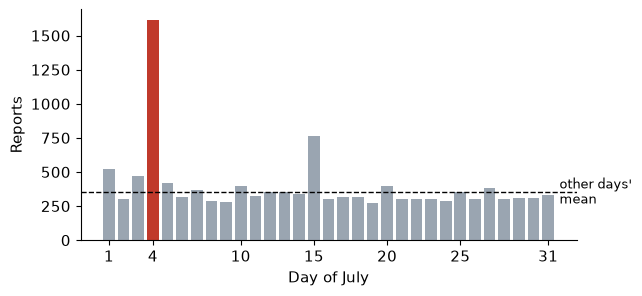

July 4th: 1,613 reports, other July days: 353 on average (4.6x)
July 5th: 422 (1.2x the remaining days)
day 15 across all months: 5.7%, day 1: 5.0%  (about 12/365 = 3.3% expected)


In [22]:
july = people[(people["date_precise"] & people["month"].eq(7)).fillna(False)]
by_day = july["day"].value_counts().reindex(range(1, 32), fill_value=0)
other_mean = by_day.drop(4).mean()

fig, ax = plt.subplots(figsize=(6.4, 3))
ax.bar(by_day.index, by_day.values, color=[RED if d == 4 else GREY for d in by_day.index])
ax.axhline(other_mean, ls="--", lw=1, color="k")
ax.text(31.5, other_mean, " other days'\n mean", va="center", fontsize=9)
ax.set_xticks([1, 4, 10, 15, 20, 25, 31])
ax.set_xlabel("Day of July")
ax.set_ylabel("Reports")
save(fig, "fig_july_days")

print(f"July 4th: {by_day[4]:,} reports, other July days: {other_mean:.0f} on average ({by_day[4] / other_mean:.1f}x)")
print(f"July 5th: {by_day[5]:,} ({by_day[5] / by_day.drop([4, 5]).mean():.1f}x the remaining days)")

precise = people[people["date_precise"]]
print(f"day 15 across all months: {precise['day'].eq(15).mean():.1%}, "
      f"day 1: {precise['day'].eq(1).mean():.1%}  (about 12/365 = 3.3% expected)")

**Takeaway:** July 4th has 1,613 reports, 4.6 times an average other July day (353). The smaller bump on the 15th isn't an event: witnesses who don't remember the day pick the 15th (5.7% of precise dates in every month, against 3.3% expected), and the 1st in the same way.

July 4th falls on a different weekday each year, so compare it with July days of the same kind (weekend or weekday). Each row below is the average number of reports per calendar date, over the years with at least 1,000 reports:

In [23]:
busy_years = per_year[per_year >= 1000].index
all_july = pd.DatetimeIndex([d for y in busy_years for d in pd.date_range(f"{y}-07-01", f"{y}-07-31")])
per_date = july.groupby("occurred_date").size().reindex(all_july, fill_value=0)
per_date = pd.DataFrame({
    "reports": per_date.values,
    "day": np.where(per_date.index.day == 4, "July 4th", "other July day"),
    "weekend": np.where(per_date.index.dayofweek >= 5, "weekend", "weekday"),
})
july_table = per_date.groupby(["weekend", "day"])["reports"].agg(dates="size", mean_reports="mean").round(1)
print(f"years used: {busy_years.min()}-{busy_years.max()} ({len(busy_years)} years)")
july_table

years used: 1995-2022 (27 years)


dates  mean_reports
weekend day                                
weekday July 4th           19          55.6
        other July day    578          10.7
weekend July 4th            8          60.9
        other July day    232          14.3

**Takeaway:** per calendar date, July 4th gets 55.6 reports on a weekday against 10.7 for other July weekdays (5.2 times), and 60.9 against 14.3 on a weekend (4.3 times), so the spike is not just July 4th falling on weekends.

### Duration

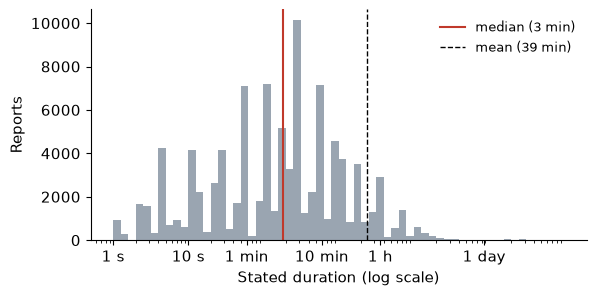

reports with a duration: 96,340
median 180 s, mean 2365 s
skewness: raw 300.4, log10 -0.19
exactly 1, 2, 3, 5, 10, 15, 20, 30 or 60 minutes: 51.7%
outside 1 s to 1e6 s (clipped in the plot only): 125


In [24]:
dur = people.loc[people["duration_ok"], "duration_seconds"]
round_values = [60, 120, 180, 300, 600, 900, 1200, 1800, 3600]

fig, ax = plt.subplots(figsize=(6.4, 3))
ax.hist(dur.clip(1, 1e6), bins=np.logspace(0, 6, 61), color=GREY)
ax.set_xscale("log")
ax.set_xticks([1, 10, 60, 600, 3600, 86400], ["1 s", "10 s", "1 min", "10 min", "1 h", "1 day"])
ax.axvline(dur.median(), color=RED, lw=1.5, label=f"median ({dur.median() / 60:.0f} min)")
ax.axvline(dur.mean(), color="k", ls="--", lw=1, label=f"mean ({dur.mean() / 60:.0f} min)")
ax.set_xlabel("Stated duration (log scale)")
ax.set_ylabel("Reports")
ax.legend(frameon=False, fontsize=9)
save(fig, "fig_duration")

print(f"reports with a duration: {len(dur):,}")
print(f"median {dur.median():.0f} s, mean {dur.mean():.0f} s")
print(f"skewness: raw {stats.skew(dur):.1f}, log10 {stats.skew(np.log10(dur)):.2f}")
print(f"exactly 1, 2, 3, 5, 10, 15, 20, 30 or 60 minutes: {dur.isin(round_values).mean():.1%}")
print(f"outside 1 s to 1e6 s (clipped in the plot only): {((dur < 1) | (dur > 1e6)).sum()}")

**Takeaway:** stated durations are extremely skewed (median 3 minutes, mean 39 minutes, skewness 300) but close to symmetric on a log scale (skewness -0.19), and 52% are round answers such as 5 or 10 minutes.

### Duration by reporting delay

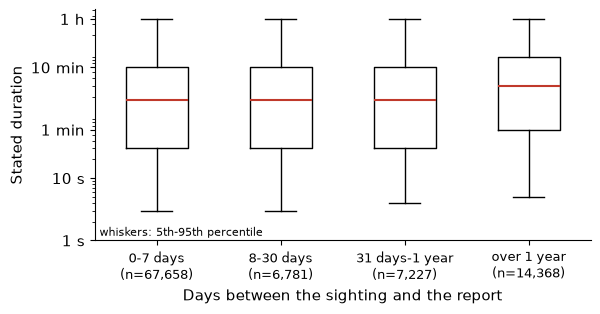

,count,25%,50%,75%
delay_band,,,,
0-7 days,67658.0,30.0,180.0,600.0
8-30 days,6781.0,30.0,180.0,600.0
31 days-1 year,7227.0,30.0,180.0,600.0
over 1 year,14368.0,60.0,300.0,900.0


In [25]:
lagged = people[people["duration_ok"] & ~people["lag_error"] & people["lag_reported_days"].notna()].copy()
band_labels = ["0-7 days", "8-30 days", "31 days-1 year", "over 1 year"]
lagged["delay_band"] = pd.cut(lagged["lag_reported_days"].astype(float), [-2, 7, 30, 365, np.inf], labels=band_labels)
groups = [lagged.loc[lagged["delay_band"] == b, "duration_seconds"] for b in band_labels]

fig, ax = plt.subplots(figsize=(6.4, 3))
ax.boxplot(groups, whis=(5, 95), showfliers=False, widths=0.5, medianprops={"color": RED, "lw": 1.5})
ax.set_xticks(range(1, 5), [f"{b}\n(n={len(g):,})" for b, g in zip(band_labels, groups)], fontsize=9)
ax.set_yscale("log")
ax.set_yticks([1, 10, 60, 600, 3600], ["1 s", "10 s", "1 min", "10 min", "1 h"])
ax.set_xlabel("Days between the sighting and the report")
ax.set_ylabel("Stated duration")
ax.text(0.01, 0.02, "whiskers: 5th-95th percentile", fontsize=8, transform=ax.transAxes)
save(fig, "fig_duration_by_delay")

lagged.groupby("delay_band", observed=True)["duration_seconds"].describe(percentiles=[0.25, 0.5, 0.75])[["count", "25%", "50%", "75%"]]

**Takeaway:** reports filed within a year of the sighting all state a median of 3 minutes; only those filed more than a year later state longer durations (median 5 minutes).

### Shapes on July 4th

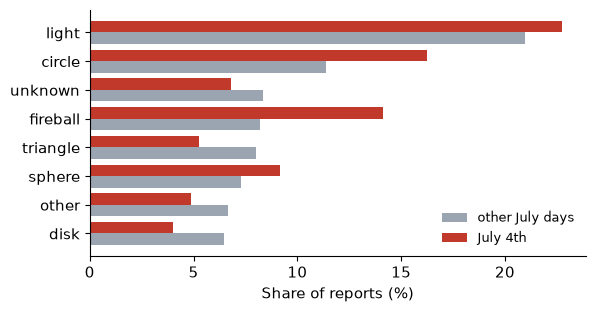

col_0,July 4th,other July days
shape_clean,,
light,22.8,21.0
circle,16.2,11.4
unknown,6.8,8.3
fireball,14.1,8.2
triangle,5.3,8.0
sphere,9.2,7.3
other,4.9,6.7
disk,4.0,6.4


In [26]:
july_shapes = pd.crosstab(july["shape_clean"], np.where(july["day"] == 4, "July 4th", "other July days"), normalize="columns")
july_shapes = july_shapes.sort_values("other July days", ascending=False).head(8).iloc[::-1]

fig, ax = plt.subplots(figsize=(6.4, 3.2))
y = np.arange(len(july_shapes))
ax.barh(y - 0.2, july_shapes["other July days"] * 100, height=0.4, color=GREY, label="other July days")
ax.barh(y + 0.2, july_shapes["July 4th"] * 100, height=0.4, color=RED, label="July 4th")
ax.set_yticks(y, july_shapes.index)
ax.set_xlabel("Share of reports (%)")
ax.legend(frameon=False, fontsize=9, loc="lower right")
save(fig, "fig_july_shapes")

(july_shapes.iloc[::-1] * 100).round(1)

**Takeaway:** July 4th reports say fireball (14.1% against 8.2%) and circle (16.2% against 11.4%) more often than other July days, while light barely changes (22.8% against 21.0%).

## 6. Hypothesis tests (confirmation set only)

Everything in this section uses the confirmation set only, without MADAR and empty-text rows.

In [27]:
conf_people = confirm[~confirm["is_junk"]].copy()
results = []
checks = []


def add_check(test, check, n, estimate, ci, p_value):
    checks.append({"test": test, "check": check, "n": n, "estimate": estimate,
                   "ci_low": ci[0], "ci_high": ci[1], "p_value": p_value})


def one_per_city_night(d):
    shuffled = d.sample(frac=1, random_state=SEED)
    place = shuffled["city"].str.strip().str.lower() + ", " + shuffled["state"].fillna("").str.strip().str.upper()
    repeat = place.notna() & shuffled["occurred_date"].notna() & pd.DataFrame(
        {"place": place, "date": shuffled["occurred_date"]}).duplicated()
    return shuffled[~repeat].sort_index()


conf_events = one_per_city_night(conf_people)
print(f"reports used: {len(conf_people):,}")
print(f"one report per city and night: {len(conf_events):,} ({len(conf_people) - len(conf_events):,} repeats set aside)")

reports used: 27,798
one report per city and night: 27,555 (243 repeats set aside)


### Test 1: Is July 4th over-represented once weekday is held fixed?

| | |
|---|---|
| $H_0$ | rate ratio $\le 1$ |
| $H_1$ | rate ratio $> 1$ |
| Significance level | $\alpha = 0.05$ |
| Side | one-sided (right) |
| Test | permutation test within year and weekday/weekend groups, 10,000 shuffles |
| Smallest difference that matters | rate ratio 1.5 |

The rate ratio is reports on July 4th divided by reports on an ordinary July day of the same year and the same kind (weekday or weekend). Only precise dates count. Days 1 and 15 are left out, since guessed dates pile up there. The years (1995-2022) were fixed on the exploration set.

In [28]:
N_PERM = N_BOOT = 10_000


def july_date_counts(d):
    july = d[(d["date_precise"] & d["month"].eq(7)).fillna(False)]
    dates = pd.DatetimeIndex([x for y in busy_years for x in pd.date_range(f"{y}-07-01", f"{y}-07-31")])
    dates = dates[~dates.day.isin([1, 15])]
    return pd.DataFrame({
        "reports": july.groupby("occurred_date").size().reindex(dates, fill_value=0).to_numpy(),
        "year": dates.year,
        "weekend": dates.dayofweek >= 5,
        "july4": dates.day == 4,
    })


def rate_ratio(a, totals, sizes):
    return (a * (sizes - 1) / sizes).sum(axis=-1) / ((totals - a) / sizes).sum(axis=-1)


def test1(d, rng):
    counts = july_date_counts(d)
    same_kind = counts.merge(counts.loc[counts["july4"], ["year", "weekend"]], on=["year", "weekend"])
    strata = [g for _, g in same_kind.groupby("year")]
    pools = [g["reports"].to_numpy() for g in strata]
    a = np.array([g.loc[g["july4"], "reports"].iloc[0] for g in strata])
    totals = np.array([x.sum() for x in pools])
    sizes = np.array([len(x) for x in pools])

    observed = rate_ratio(a, totals, sizes)
    shuffled = rate_ratio(np.column_stack([rng.choice(x, size=N_PERM) for x in pools]), totals, sizes)
    p_value = (1 + (shuffled >= observed).sum()) / (1 + N_PERM)

    pick = rng.integers(0, len(strata), size=(N_BOOT, len(strata)))
    ci = np.percentile(rate_ratio(a[pick], totals[pick], sizes[pick]), [2.5, 97.5])
    return {"counts": counts, "same_kind": same_kind, "rr": observed, "p": p_value, "ci": ci, "shuffled": shuffled}


t1 = test1(conf_people, np.random.default_rng(SEED))
same_kind = t1["same_kind"]
on4 = same_kind[same_kind["july4"]]
ordinary = same_kind[~same_kind["july4"]]

print(f"years: {on4['year'].nunique()}  July 4ths: {len(on4)}  comparison dates: {len(ordinary)}")
print(f"reports per July 4th: {on4['reports'].mean():.1f}   per comparison date: {ordinary['reports'].mean():.2f}")
print(f"\nrate ratio: {t1['rr']:.2f}")
print(f"95% CI (bootstrap over years): {t1['ci'][0]:.2f} to {t1['ci'][1]:.2f}")
print(f"permutation p-value: {t1['p']:.5f}  (largest shuffled ratio: {t1['shuffled'].max():.2f})")
print(f"decision at 0.05: {'reject H0' if t1['p'] < 0.05 else 'fail to reject H0'}")
print(f"CI entirely above 1.5: {t1['ci'][0] > 1.5}")

years: 27  July 4ths: 27  comparison dates: 436
reports per July 4th: 15.8   per comparison date: 2.69

rate ratio: 5.64
95% CI (bootstrap over years): 4.14 to 7.18
permutation p-value: 0.00010  (largest shuffled ratio: 2.84)
decision at 0.05: reject H0
CI entirely above 1.5: True


#### Other tests on the same question

In [29]:
counts = t1["counts"]
n4 = int(counts.loc[counts["july4"], "reports"].sum())
n_other = int(counts.loc[~counts["july4"], "reports"].sum())
p0 = counts["july4"].mean()
crude_rr = (n4 / counts["july4"].sum()) / (n_other / (~counts["july4"]).sum())

chi = stats.chisquare([n4, n_other], [(n4 + n_other) * p0, (n4 + n_other) * (1 - p0)])
poisson = stats.binomtest(n4, n4 + n_other, p0, alternative="greater")

within = ordinary.groupby("year")["reports"].agg(["mean", "var"])
pooled = counts.loc[~counts["july4"], "reports"]
print(f"variance / mean of daily counts (Poisson assumes 1):")
print(f"  within a year and weekday kind: {(within['var'] / within['mean']).mean():.2f}")
print(f"  pooled over years:              {pooled.var() / pooled.mean():.2f}")

pd.DataFrame([
    ("stratified permutation (chosen)", round(t1["rr"], 3), "n/a", t1["p"], round(t1["rr"], 2), "yes"),
    ("chi-square goodness of fit", round(chi.statistic, 1), 1, chi.pvalue, round(crude_rr, 2), "no"),
    ("exact Poisson (binomial) test", n4, "n/a", poisson.pvalue, round(crude_rr, 2), "no"),
], columns=["test", "statistic", "df", "p_value", "rate_ratio", "holds year and weekday fixed"])

variance / mean of daily counts (Poisson assumes 1):
  within a year and weekday kind: 1.37
  pooled over years:              2.02


,test,statistic,df,p_value,rate_ratio,holds year and weekday fixed
0,stratified permutation (chosen),5.643,n/a,9.999000e-05,5.64,yes
1,chi-square goodness of fit,1384.700,1,4.537528e-303,5.74,no
2,exact Poisson (binomial) test,426.000,n/a,4.763267e-161,5.74,no


#### Checks

Each test is repeated without NUFORC's hoax reports. Where several people may have reported the same event, it is also repeated with one report per city and night.

In [30]:
t1_nohoax = test1(conf_people[~conf_people["nuforc_hoax"]], np.random.default_rng(SEED))
t1_events = test1(conf_events, np.random.default_rng(SEED))
for name, r in [("all reports", t1), ("without hoax reports", t1_nohoax), ("one report per city and night", t1_events)]:
    print(f"{name:30s} rate ratio {r['rr']:.2f}, 95% CI {r['ci'][0]:.2f} to {r['ci'][1]:.2f}, p = {r['p']:.5f}")
    add_check("1", name, int(r["same_kind"]["reports"].sum()), r["rr"], r["ci"], r["p"])

results.append({
    "test": "1: July 4th excess", "method": "stratified permutation", "statistic": t1["rr"], "df": None,
    "p_value": t1["p"], "estimate": t1["rr"], "ci_low": t1["ci"][0], "ci_high": t1["ci"][1], "threshold": 1.5,
})
pd.DataFrame(results).to_csv(OUT_DIR / "test_results.csv", index=False)

all reports                    rate ratio 5.64, 95% CI 4.14 to 7.18, p = 0.00010
without hoax reports           rate ratio 5.63, 95% CI 4.11 to 7.19, p = 0.00010
one report per city and night  rate ratio 5.52, 95% CI 4.05 to 7.00, p = 0.00010


#### Result

| | |
|---|---|
| Estimate | rate ratio 5.64 (15.8 reports per July 4th, 2.69 per ordinary July day of the same kind) |
| 95% confidence interval | 4.14 to 7.18 |
| Test statistic (df) | rate ratio 5.64 (no df, permutation test) |
| p-value | 0.0001, the smallest possible with 10,000 shuffles; no shuffle went above 2.84 |
| Decision | reject $H_0$ |

July 4th gets more than five times the reports of an ordinary July day of the same kind, and the whole interval is above 1.5, so the excess matters. The chi-square and Poisson tests agree, but their p-values ($10^{-303}$ and $10^{-161}$) shouldn't be trusted: daily counts vary 1.4 to 2 times more than those tests assume. Leaving out hoax reports (5.63) or keeping one report per city and night (5.52, 95% CI 4.05 to 7.00) changes nothing.

### Test 2: Do late filers state longer durations than early filers?

| | |
|---|---|
| $H_0$ | late durations are not larger: $P(\text{late} > \text{early}) \le 0.5$ |
| $H_1$ | late durations are larger: $P(\text{late} > \text{early}) > 0.5$ |
| Significance level | $\alpha = 0.05$ |
| Side | one-sided (right) |
| Test | Mann-Whitney U |
| Smallest difference that matters | late durations 1.5 times as long (ratio of geometric means) |

Early means reported on the same night or within 7 days of the sighting (a delay of -1 to 7 days; -1 is a same-night report, see cleaning), late more than 30 days after (Reported minus Occurred). Rows flagged `lag_error` are left out, and a check below also leaves out the -1 day reports. The test works on ranks because durations are extremely skewed. The size of the difference is the ratio of geometric means: how many times longer late durations are on the log scale. Its confidence interval comes from a Welch t-test on log durations, so it describes the geometric means, not the Mann-Whitney effect. The Mann-Whitney effect, $P(\text{late} > \text{early})$, gets its own bootstrap interval.

In [31]:
N_BOOT_RANKS = 2_000


def delay_groups(d, min_lag=-1):
    usable = d[d["duration_ok"] & ~d["lag_error"] & d["lag_reported_days"].notna()]
    lag = usable["lag_reported_days"]
    return (usable.loc[lag.between(min_lag, 7), "duration_seconds"].to_numpy(),
            usable.loc[lag.gt(30), "duration_seconds"].to_numpy())


def superiority(late, early):
    ranks = stats.rankdata(np.r_[late, early])
    return (ranks[:len(late)].sum() - len(late) * (len(late) + 1) / 2) / (len(late) * len(early))


def superiority_ci(late, early, rng):
    boot = [superiority(rng.choice(late, len(late)), rng.choice(early, len(early))) for _ in range(N_BOOT_RANKS)]
    return np.percentile(boot, [2.5, 97.5])


def test2(d, min_lag=-1):
    early, late = delay_groups(d, min_lag)
    mw = stats.mannwhitneyu(late, early, alternative="greater", method="asymptotic")
    welch = stats.ttest_ind(np.log(late), np.log(early), equal_var=False)
    ci = welch.confidence_interval(0.95)
    return {
        "early": early, "late": late, "mw": mw,
        "superiority": mw.statistic / (len(late) * len(early)),
        "ratio": np.exp(np.log(late).mean() - np.log(early).mean()), "ci": (np.exp(ci.low), np.exp(ci.high)),
    }


t2 = test2(conf_people)
early, late = t2["early"], t2["late"]
gmean = lambda x: np.exp(np.log(x).mean())

print(f"early: n = {len(early):,}, median {np.median(early):.0f} s, geometric mean {gmean(early):.0f} s")
print(f"late:  n = {len(late):,}, median {np.median(late):.0f} s, geometric mean {gmean(late):.0f} s")
print(f"\nratio of geometric means: {t2['ratio']:.2f}")
print(f"95% CI: {t2['ci'][0]:.2f} to {t2['ci'][1]:.2f}")
print(f"Mann-Whitney U = {t2['mw'].statistic:,.0f}, p = {t2['mw'].pvalue:.2e}")
t2_sup_ci = superiority_ci(late, early, np.random.default_rng(SEED))
print(f"P(late > early): {t2['superiority']:.3f}, 95% CI {t2_sup_ci[0]:.3f} to {t2_sup_ci[1]:.3f} (bootstrap)")
print(f"early reports with a delay of -1 day (same night): {len(early) - len(delay_groups(conf_people, 0)[0]):,}")
print(f"decision at 0.05: {'reject H0' if t2['mw'].pvalue < 0.05 else 'fail to reject H0'}")
print(f"CI entirely above 1.5: {t2['ci'][0] > 1.5}   CI entirely below 1.5: {t2['ci'][1] < 1.5}")

early: n = 16,826, median 180 s, geometric mean 141 s


late:  n = 5,470, median 210 s, geometric mean 171 s

ratio of geometric means: 1.21
95% CI: 1.13 to 1.29
Mann-Whitney U = 48,319,183, p = 1.28e-08


P(late > early): 0.525, 95% CI 0.516 to 0.533 (bootstrap)
early reports with a delay of -1 day (same night): 442
decision at 0.05: reject H0
CI entirely above 1.5: False   CI entirely below 1.5: True


#### Other tests on the same question

In [32]:
log_e, log_l = np.log(early), np.log(late)
welch_log = stats.ttest_ind(log_l, log_e, equal_var=False, alternative="greater")
pooled_log = stats.ttest_ind(log_l, log_e, equal_var=True, alternative="greater")
welch_raw = stats.ttest_ind(late, early, equal_var=False, alternative="greater")
mood = stats.median_test(late, early)
ks = stats.ks_2samp(late, early)
levene = stats.levene(log_l, log_e)

print(f"Levene test on log durations: W = {levene.statistic:.1f}, p = {levene.pvalue:.2e}")
print(f"skewness: raw {stats.skew(np.r_[early, late]):.0f}, log {stats.skew(np.r_[log_e, log_l]):.2f}")

pd.DataFrame([
    ("Mann-Whitney U (chosen)", t2["mw"].statistic, "n/a", t2["mw"].pvalue, "one"),
    ("Welch t on log duration", welch_log.statistic, round(welch_log.df), welch_log.pvalue, "one"),
    ("pooled t on log duration", pooled_log.statistic, round(pooled_log.df), pooled_log.pvalue, "one"),
    ("Welch t on raw duration", welch_raw.statistic, round(welch_raw.df), welch_raw.pvalue, "one"),
    ("Mood's median test", mood.statistic, 1, mood.pvalue, "two"),
    ("Kolmogorov-Smirnov", ks.statistic, "n/a", ks.pvalue, "two"),
], columns=["test", "statistic", "df", "p_value", "sided"]).round({"statistic": 3})

Levene test on log durations: W = 12.5, p = 4.12e-04
skewness: raw 76, log -0.18


,test,statistic,df,p_value,sided
0,Mann-Whitney U (chosen),4.831918e+07,n/a,1.276569e-08,one
1,Welch t on log duration,5.817000e+00,9545,3.097269e-09,one
2,pooled t on log duration,5.723000e+00,22294,5.315433e-09,one
3,Welch t on raw duration,1.587000e+00,6719,5.623601e-02,one
4,Mood's median test,2.698300e+01,1,2.052646e-07,two
5,Kolmogorov-Smirnov,4.200000e-02,n/a,7.751350e-07,two


#### Checks

Each test is repeated without NUFORC's hoax reports. Where several people may have reported the same event, it is also repeated with one report per city and night.

In [33]:
t2_nohoax = test2(conf_people[~conf_people["nuforc_hoax"]])
t2_sameday = test2(conf_people, min_lag=0)
for name, r in [("all reports", t2), ("without hoax reports", t2_nohoax), ("early group without -1 day reports", t2_sameday)]:
    print(f"{name:36s} ratio {r['ratio']:.2f}, 95% CI {r['ci'][0]:.2f} to {r['ci'][1]:.2f}, "
          f"P(late > early) {r['superiority']:.3f}, p = {r['mw'].pvalue:.2e}  (early n = {len(r['early']):,})")
    add_check("2", name, len(r["early"]) + len(r["late"]), r["ratio"], r["ci"], r["mw"].pvalue)

results.append({
    "test": "2: late vs early filers", "method": "Mann-Whitney U", "statistic": t2["mw"].statistic, "df": None,
    "p_value": t2["mw"].pvalue, "estimate": t2["ratio"], "ci_low": t2["ci"][0], "ci_high": t2["ci"][1], "threshold": 1.5,
})
pd.DataFrame(results).to_csv(OUT_DIR / "test_results.csv", index=False)

all reports                          ratio 1.21, 95% CI 1.13 to 1.29, P(late > early) 0.525, p = 1.28e-08  (early n = 16,826)
without hoax reports                 ratio 1.21, 95% CI 1.13 to 1.29, P(late > early) 0.525, p = 1.06e-08  (early n = 16,698)
early group without -1 day reports   ratio 1.20, 95% CI 1.13 to 1.28, P(late > early) 0.525, p = 2.11e-08  (early n = 16,384)


#### Result

| | |
|---|---|
| Estimate | late durations 1.21 times as long (geometric mean 171 s against 141 s; medians 210 s and 180 s) |
| 95% confidence interval | 1.13 to 1.29 for the ratio (Welch t on log durations); 0.516 to 0.533 for $P(\text{late} > \text{early})$ (bootstrap) |
| Test statistic (df) | U = 48,319,183 (no df); $P(\text{late} > \text{early}) = 0.525$ |
| p-value | $1.3 \times 10^{-8}$ |
| Decision | reject $H_0$ |

Late filers do state longer durations, but only about 21% longer, and the whole interval is below 1.5, so the difference is real but too small to matter. The log-scale t-tests, Mood's median test and Kolmogorov-Smirnov agree. A t-test on raw durations doesn't (p = 0.056): a few multi-day reports swamp it, which is why ranks or logs are needed here. The two intervals describe different things: the first is for the geometric means, the second for the Mann-Whitney effect, and both point the same way. Leaving out hoax reports (1.21) or the 442 same-night reports with a delay of -1 day (1.20, 95% CI 1.13 to 1.28) changes nothing.

### Test 3: Does duration rise steadily with delay, or only for very late reports?

| | |
|---|---|
| $H_0$ | durations have the same distribution in all four delay bands |
| $H_1$ | at least one band differs |
| Significance level | $\alpha = 0.05$ |
| Side | no direction for the overall test; each follow-up step is one-sided (later band longer) |
| Test | Kruskal-Wallis, then Mann-Whitney between neighbouring bands with Holm correction |
| Smallest difference that matters | a ratio of geometric means of 1.5 between neighbouring bands |

The bands are the ones from the exploration plot: 0-7 days, 8-30 days, 31 days-1 year, over 1 year.

In [34]:
def band_groups(d, min_lag=-1):
    usable = d[d["duration_ok"] & ~d["lag_error"] & d["lag_reported_days"].notna()]
    usable = usable[usable["lag_reported_days"] >= min_lag]
    bands = pd.cut(usable["lag_reported_days"].astype(float), [-2, 7, 30, 365, np.inf], labels=band_labels)
    return usable, [usable.loc[bands == b, "duration_seconds"].to_numpy() for b in band_labels]


def holm(p):
    p = np.asarray(p, dtype=float)
    adjusted, running = np.empty(len(p)), 0.0
    for rank, i in enumerate(np.argsort(p)):
        running = max(running, (len(p) - rank) * p[i])
        adjusted[i] = min(1.0, running)
    return adjusted


def test3(d, min_lag=-1):
    usable, groups = band_groups(d, min_lag)
    kw = stats.kruskal(*groups)
    steps = []
    for (name_a, a), (name_b, b) in zip(zip(band_labels, groups), zip(band_labels[1:], groups[1:])):
        mw = stats.mannwhitneyu(b, a, alternative="greater", method="asymptotic")
        ci = stats.ttest_ind(np.log(b), np.log(a), equal_var=False).confidence_interval(0.95)
        steps.append({"step": f"{name_a} to {name_b}", "ratio": np.exp(np.log(b).mean() - np.log(a).mean()),
                      "ci_low": np.exp(ci.low), "ci_high": np.exp(ci.high), "U": mw.statistic, "p": mw.pvalue})
    steps = pd.DataFrame(steps)
    steps["p_holm"] = holm(steps["p"])
    return {"usable": usable, "groups": groups, "kw": kw, "steps": steps}


t3 = test3(conf_people)
n_total = sum(len(g) for g in t3["groups"])
print(pd.DataFrame({
    "band": band_labels,
    "n": [len(g) for g in t3["groups"]],
    "median_s": [np.median(g) for g in t3["groups"]],
    "geometric_mean_s": [round(gmean(g)) for g in t3["groups"]],
}).to_string(index=False))
print(f"\nKruskal-Wallis H = {t3['kw'].statistic:.1f}, df = 3, p = {t3['kw'].pvalue:.2e}")
print(f"effect size (epsilon squared, H / (n - 1)): {t3['kw'].statistic / (n_total - 1):.4f}")
print(f"decision at 0.05: {'reject H0' if t3['kw'].pvalue < 0.05 else 'fail to reject H0'}\n")
t3["steps"].round({"ratio": 2, "ci_low": 2, "ci_high": 2})

          band     n  median_s  geometric_mean_s
      0-7 days 16826     180.0               141
     8-30 days  1657     180.0               138
31 days-1 year  1777     180.0               130
   over 1 year  3693     300.0               195

Kruskal-Wallis H = 79.4, df = 3, p = 4.11e-17
effect size (epsilon squared, H / (n - 1)): 0.0033
decision at 0.05: reject H0



,step,ratio,ci_low,ci_high,U,p,p_holm
0,0-7 days to 8-30 days,0.98,0.87,1.09,13868720.0,6.353544e-01,1.000000e+00
1,8-30 days to 31 days-1 year,0.94,0.82,1.09,1440428.5,8.637791e-01,1.000000e+00
2,31 days-1 year to over 1 year,1.49,1.33,1.68,3660498.0,1.896468e-12,5.689405e-12


#### Other tests on the same question

In [35]:
logs = [np.log(g) for g in t3["groups"]]
anova = stats.f_oneway(*logs)
ag = stats.alexandergovern(*logs)
usable = t3["usable"]
rho = stats.spearmanr(usable["lag_reported_days"].astype(float), usable["duration_seconds"])
t_rho = rho.statistic * np.sqrt((len(usable) - 2) / (1 - rho.statistic ** 2))

pd.DataFrame([
    ("Kruskal-Wallis (chosen)", round(t3["kw"].statistic, 2), "3", t3["kw"].pvalue),
    ("one-way ANOVA on log duration", round(anova.statistic, 2), f"3, {n_total - 4}", anova.pvalue),
    ("Alexander-Govern on log duration", round(ag.statistic, 2), "3", ag.pvalue),
    (f"Spearman correlation (rho = {rho.statistic:.3f})", round(t_rho, 2), f"{len(usable) - 2}", rho.pvalue),
], columns=["test", "statistic", "df", "p_value"])

,test,statistic,df,p_value
0,Kruskal-Wallis (chosen),79.41,3,4.106529e-17
1,one-way ANOVA on log duration,25.62,"3, 23949",1.545975e-16
2,Alexander-Govern on log duration,81.67,3,1.347749e-17
3,Spearman correlation (rho = 0.045),6.95,23951,3.825320e-12


#### Checks

Each test is repeated without NUFORC's hoax reports. Where several people may have reported the same event, it is also repeated with one report per city and night.

In [36]:
t3_nohoax = test3(conf_people[~conf_people["nuforc_hoax"]])
t3_sameday = test3(conf_people, min_lag=0)
for name, r in [("all reports", t3), ("without hoax reports", t3_nohoax), ("first band without -1 day reports", t3_sameday)]:
    last = r["steps"].iloc[-1]
    print(f"{name:34s} H = {r['kw'].statistic:.1f}, p = {r['kw'].pvalue:.2e}; "
          f"step ratios {', '.join(f'{x:.2f}' for x in r['steps']['ratio'])}; last step CI {last['ci_low']:.2f} to {last['ci_high']:.2f}")
    add_check("3", name, sum(len(g) for g in r["groups"]), last["ratio"], (last["ci_low"], last["ci_high"]), r["kw"].pvalue)

results.append({
    "test": "3: duration across delay bands", "method": "Kruskal-Wallis", "statistic": t3["kw"].statistic, "df": 3,
    "p_value": t3["kw"].pvalue, "estimate": None, "ci_low": None, "ci_high": None, "threshold": 1.5,
})
t3["steps"].to_csv(OUT_DIR / "test3_steps.csv", index=False)
pd.DataFrame(results).to_csv(OUT_DIR / "test_results.csv", index=False)

all reports                        H = 79.4, p = 4.11e-17; step ratios 0.98, 0.94, 1.49; last step CI 1.33 to 1.68
without hoax reports               H = 77.9, p = 8.69e-17; step ratios 0.97, 0.95, 1.48; last step CI 1.32 to 1.67
first band without -1 day reports  H = 78.6, p = 5.98e-17; step ratios 0.97, 0.94, 1.49; last step CI 1.33 to 1.68


#### Result

| | |
|---|---|
| Estimate | step ratios: 0.98 (0-7 to 8-30 days), 0.94 (8-30 days to 1 year), 1.49 (1 year to over 1 year) |
| 95% confidence interval | 0.87 to 1.09, 0.82 to 1.09, 1.33 to 1.68 |
| Test statistic (df) | Kruskal-Wallis H = 79.4 (3) |
| p-value | $4.1 \times 10^{-17}$; steps after Holm: 1.0, 1.0, $5.7 \times 10^{-12}$ |
| Decision | reject $H_0$ |

Duration doesn't rise steadily: it stays flat for the first year and then jumps by about half for reports filed more than a year later. That jump's interval (1.33 to 1.68) straddles 1.5, so it may or may not reach the size we said matters. This also explains Test 2's small effect: its late group mixes a flat band with the jump. ANOVA and Alexander-Govern on log duration agree; the Spearman correlation is tiny (0.045) because it looks for a steady trend that isn't there. The step intervals come from Welch t-tests on log durations, so they describe geometric means; the Holm p-values come from the Mann-Whitney tests. Leaving out hoax reports or the -1 day reports changes nothing (last step 1.48 and 1.49).

### Test 4: Do July 4th reports say "fireball" more often than other July days?

| | |
|---|---|
| $H_0$ | $p_{\text{July 4}} \le p_{\text{other}}$ |
| $H_1$ | $p_{\text{July 4}} > p_{\text{other}}$ |
| Significance level | $\alpha = 0.05$ |
| Side | one-sided (right) |
| Test | two-proportion z-test |
| Smallest difference that matters | 3 percentage points |

$p$ is the share of reports with the shape "fireball". The July dates are the same as in Test 1: precise dates, 1995-2022, without days 1 and 15.

In [37]:
def test4(d):
    july = d[(d["date_precise"] & d["month"].eq(7) & d["year"].isin(busy_years) & ~d["day"].isin([1, 15])).fillna(False)]
    on4 = july["day"].eq(4).to_numpy()
    fireball = july["shape_clean"].eq("fireball").to_numpy()
    x1, n1 = int((fireball & on4).sum()), int(on4.sum())
    x2, n2 = int((fireball & ~on4).sum()), int((~on4).sum())
    p1, p2 = x1 / n1, x2 / n2
    pooled = (x1 + x2) / (n1 + n2)
    z = (p1 - p2) / np.sqrt(pooled * (1 - pooled) * (1 / n1 + 1 / n2))
    se = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
    half = stats.norm.ppf(0.975) * se
    return {"july": july, "on4": on4, "table": np.array([[x1, n1 - x1], [x2, n2 - x2]]),
            "p1": p1, "p2": p2, "diff": p1 - p2, "ci": (p1 - p2 - half, p1 - p2 + half), "z": z, "p": stats.norm.sf(z)}


t4 = test4(conf_people)
(x1, _), (x2, _) = t4["table"]
print(f"July 4th: {x1} fireballs of {t4['table'][0].sum()} reports ({t4['p1']:.1%})")
print(f"other July days: {x2} fireballs of {t4['table'][1].sum()} reports ({t4['p2']:.1%})")
print(f"\ndifference: {t4['diff'] * 100:.1f} percentage points")
print(f"95% CI: {t4['ci'][0] * 100:.1f} to {t4['ci'][1] * 100:.1f} percentage points")
print(f"z = {t4['z']:.2f}, p = {t4['p']:.2e}")
print(f"decision at 0.05: {'reject H0' if t4['p'] < 0.05 else 'fail to reject H0'}")
print(f"CI entirely above 3 points: {t4['ci'][0] > 0.03}")

July 4th: 60 fireballs of 426 reports (14.1%)
other July days: 185 fireballs of 2077 reports (8.9%)

difference: 5.2 percentage points
95% CI: 1.7 to 8.7 percentage points
z = 3.28, p = 5.27e-04
decision at 0.05: reject H0
CI entirely above 3 points: False


#### Other tests on the same question

In [38]:
chi_2x2 = stats.chi2_contingency(t4["table"], correction=False)
fisher = stats.fisher_exact(t4["table"], alternative="greater")
shape_table = pd.crosstab(t4["july"]["shape_group"], t4["on4"])
chi_all = stats.chi2_contingency(shape_table)
print(f"smallest expected count in the full shape table: {chi_all.expected_freq.min():.1f}")

pd.DataFrame([
    ("two-proportion z-test (chosen)", round(t4["z"], 3), "n/a", t4["p"], "one"),
    ("chi-square on the 2x2 table", round(chi_2x2.statistic, 3), chi_2x2.dof, chi_2x2.pvalue, "two"),
    (f"Fisher's exact (odds ratio {fisher.statistic:.2f})", fisher.statistic.round(3), "n/a", fisher.pvalue, "one"),
    ("chi-square on all shape groups", round(chi_all.statistic, 1), chi_all.dof, chi_all.pvalue, "two"),
], columns=["test", "statistic", "df", "p_value", "sided"])

smallest expected count in the full shape table: 2.4


,test,statistic,df,p_value,sided
0,two-proportion z-test (chosen),3.276,n/a,0.000527,one
1,chi-square on the 2x2 table,10.731,1,0.001053,two
2,Fisher's exact (odds ratio 1.68),1.677,n/a,0.001084,one
3,chi-square on all shape groups,52.100,18,0.000036,two


#### Checks

Each test is repeated without NUFORC's hoax reports. Where several people may have reported the same event, it is also repeated with one report per city and night. Reports from the same date or year may also move together (one year's fad, one night's display), which the z-test ignores, so the interval is also found by resampling whole dates or whole years.

In [39]:
t4_nohoax = test4(conf_people[~conf_people["nuforc_hoax"]])
t4_events = test4(conf_events)

july = t4["july"].assign(fireball=t4["july"]["shape_clean"].eq("fireball"), on4=t4["on4"])


def clustered_ci(by, rng):
    g = july.groupby([by, "on4"])["fireball"].agg(["size", "sum"]).unstack(fill_value=0)
    if by == "occurred_date":
        g4, go = g[g[("size", True)] > 0], g[g[("size", False)] > 0]
        i4, io = rng.integers(0, len(g4), (N_BOOT, len(g4))), rng.integers(0, len(go), (N_BOOT, len(go)))
    else:
        g4 = go = g
        i4 = io = rng.integers(0, len(g), (N_BOOT, len(g)))
    boot = (g4[("sum", True)].to_numpy()[i4].sum(1) / g4[("size", True)].to_numpy()[i4].sum(1)
            - go[("sum", False)].to_numpy()[io].sum(1) / go[("size", False)].to_numpy()[io].sum(1))
    return np.percentile(boot, [2.5, 97.5]), (boot <= 0).mean()


date_ci, date_below = clustered_ci("occurred_date", np.random.default_rng(SEED))
year_ci, year_below = clustered_ci("year", np.random.default_rng(SEED))

rows = [
    ("all reports", t4, t4["ci"], t4["p"]),
    ("without hoax reports", t4_nohoax, t4_nohoax["ci"], t4_nohoax["p"]),
    ("one report per city and night", t4_events, t4_events["ci"], t4_events["p"]),
    ("dates resampled instead of reports", t4, date_ci, None),
    ("years resampled instead of reports", t4, year_ci, None),
]
for name, r, ci, p_value in rows:
    p_text = f"p = {p_value:.2e}" if p_value is not None else ""
    print(f"{name:36s} difference {r['diff'] * 100:.1f} points, 95% CI {ci[0] * 100:.1f} to {ci[1] * 100:.1f}  {p_text}")
    add_check("4", name, int(r["table"].sum()), r["diff"], ci, p_value)
print(f"\nshare of resamples with no difference or less: dates {date_below:.3f}, years {year_below:.3f}")

results.append({
    "test": "4: fireball share on July 4th", "method": "two-proportion z-test", "statistic": t4["z"], "df": None,
    "p_value": t4["p"], "estimate": t4["diff"], "ci_low": t4["ci"][0], "ci_high": t4["ci"][1], "threshold": 0.03,
})
pd.DataFrame(results).to_csv(OUT_DIR / "test_results.csv", index=False)

all reports                          difference 5.2 points, 95% CI 1.7 to 8.7  p = 5.27e-04
without hoax reports                 difference 5.2 points, 95% CI 1.7 to 8.8  p = 5.08e-04
one report per city and night        difference 4.8 points, 95% CI 1.3 to 8.4  p = 1.34e-03
dates resampled instead of reports   difference 5.2 points, 95% CI -1.5 to 11.0  
years resampled instead of reports   difference 5.2 points, 95% CI -0.3 to 10.4  

share of resamples with no difference or less: dates 0.065, years 0.031


#### Result

| | |
|---|---|
| Estimate | +5.2 percentage points (14.1% fireball on July 4th, 8.9% on other July days) |
| 95% confidence interval | 1.7 to 8.7 percentage points |
| Test statistic (df) | z = 3.28 (no df) |
| p-value | $5.3 \times 10^{-4}$ |
| Decision | reject $H_0$ |

July 4th reports are more likely to describe a fireball, which fits people seeing fireworks or lanterns. The interval runs from 1.7 to 8.7 points, so the difference is real but we can't say it clears the 3 points we set. The 2x2 chi-square and Fisher's exact test agree. The chi-square on all shape groups also rejects, but some expected counts are below 5 (smallest 2.4), so it's less reliable. Leaving out hoax reports (5.2 points) or keeping one report per city and night (4.8 points, 95% CI 1.3 to 8.4, p = 0.0013) changes little. But the z-test treats every report as independent, and reports from the same date or year are not: the fireball share swings a lot between years (it peaks in 2010-2014, the years of sky lanterns). Resampling whole dates gives a 95% interval of -1.5 to 11.0 points, and resampling whole years gives -0.3 to 10.4. Both include zero, so this result is weaker than the z-test suggests and should be read as suggestive, not firm.

### Correcting for four tests (Holm)

In [40]:
summary = pd.DataFrame(results)
summary["p_holm"] = holm(summary["p_value"])
summary["reject_after_holm"] = summary["p_holm"] < 0.05
summary.to_csv(OUT_DIR / "test_results.csv", index=False)
summary[["test", "method", "statistic", "df", "p_value", "p_holm", "reject_after_holm"]]

,test,method,statistic,df,p_value,p_holm,reject_after_holm
0,1: July 4th excess,stratified permutation,5.643350e+00,NaN,9.999000e-05,1.999800e-04,True
1,2: late vs early filers,Mann-Whitney U,4.831918e+07,NaN,1.276569e-08,3.829706e-08,True
2,3: duration across delay bands,Kruskal-Wallis,7.941051e+01,3.0,4.106529e-17,1.642611e-16,True
3,4: fireball share on July 4th,two-proportion z-test,3.275840e+00,NaN,5.267415e-04,5.267415e-04,True


All four tests still reject $H_0$ after Holm's correction for running four tests.

### All checks

In [41]:
robustness = pd.DataFrame(checks)
robustness.to_csv(OUT_DIR / "robustness_checks.csv", index=False)
robustness.round({"estimate": 3, "ci_low": 3, "ci_high": 3})

,test,check,n,estimate,ci_low,ci_high,p_value
0,1,all reports,1601,5.643,4.136,7.175,9.999000e-05
1,1,without hoax reports,1592,5.632,4.107,7.195,9.999000e-05
2,1,one report per city and night,1578,5.519,4.055,7.003,9.999000e-05
3,2,all reports,22296,1.208,1.133,1.287,1.276569e-08
4,2,without hoax reports,22128,1.210,1.135,1.289,1.062708e-08
5,2,early group without -1 day reports,21854,1.204,1.130,1.284,2.114345e-08
6,3,all reports,23953,1.492,1.326,1.680,4.106529e-17
7,3,without hoax reports,23768,1.483,1.316,1.670,8.694110e-17
8,3,first band without -1 day reports,23511,1.492,1.326,1.680,5.982351e-17
9,4,all reports,2503,0.052,0.017,0.087,5.267415e-04
